# Evaluación de modelos en selección sobre árboles

Activa la GPU en *Entorno de ejecución > Cambiar tipo de entorno*. Luego ejecuta todo, o edita primero la celda de configuración. Todos los modelos reciben los mismos árboles.

In [5]:
!pip install -q -U transformers accelerate mistral-common
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-0134ecae-6e94-f3e6-3acc-012d094a8f09)


## Código del ambiente

In [ ]:
!mkdir -p seleccion_arbol

In [ ]:
%%writefile seleccion_arbol/verificador.py
def leer_datos():
    n, c = map(int, input().split())
    ganancias = list(map(int, input().split()))
    aristas = [[] for _ in range(n)]
    for _ in range(n - 1):
        a, b = map(int, input().split())
        aristas[a - 1].append(b - 1)
        aristas[b - 1].append(a - 1)
    return n, c, ganancias, aristas

def retornar_respuesta(costo):
    print(costo)


def calcular_optimo(n, c, ganancias, aristas):
    # Recorro el arbol para inventarme un orden cualquiera
    padre = [-10000] * n
    orden = [0]
    for nodo_padre in orden:
        for nodo_hijo in aristas[nodo_padre]:
            if nodo_hijo != padre[nodo_padre]:
                padre[nodo_hijo] = nodo_padre
                orden.append(nodo_hijo)

    no_elegir = [0] * n
    elegir = ganancias[:]
    for nodo_padre in reversed(orden[1:]):
        p = padre[nodo_padre]
        # Si no elijo ahora
        # ¿Me conviene haber elegido antes o no?
        no_elegir[p] += max(no_elegir[nodo_padre], elegir[nodo_padre])

        # Si se me ocurre elegir este
        # 1) No elijo el anterior -> Salgo gratis
        # 2) Si elijo el anterior -> Pago 2c
        elegir[p] += max(no_elegir[nodo_padre], elegir[nodo_padre] - 2 * c)

    return max(no_elegir[0], elegir[0])


def solve():
    n, c, ganancias, aristas = leer_datos()
    print(calcular_optimo(n, c, ganancias, aristas))


if __name__ == '__main__':
    solve()


Writing seleccion_arbol/verificador.py


In [ ]:
%%writefile seleccion_arbol/instancia.py
from dataclasses import dataclass

from verificador import calcular_optimo


@dataclass(frozen=True)
class Instancia:
    # Los nodos se numeran desde 1: valores[0] es el valor del nodo 1.
    valores: tuple[int, ...]
    aristas: tuple[tuple[int, int], ...]
    costo: int

    @property
    def cantidad_nodos(self) -> int:
        return len(self.valores)

    def vecinos(self) -> dict[int, list[int]]:
        vecinos = {nodo: [] for nodo in range(1, self.cantidad_nodos + 1)}
        for a, b in self.aristas:
            vecinos[a].append(b)
            vecinos[b].append(a)
        return vecinos

    def puntaje(self, seleccion: set[int]) -> int:
        # Cada nodo elegido aporta su valor, menos el costo por cada vecino también elegido.
        vecinos = self.vecinos()
        return sum(
            self.valores[nodo - 1] - self.costo * sum(vecino in seleccion for vecino in vecinos[nodo])
            for nodo in seleccion
        )

    def puntaje_voraz(self) -> int:
        # La regla simple: elegir todos los nodos positivos, o ninguno si eso resta puntos.
        positivos = {i + 1 for i, valor in enumerate(self.valores) if valor > 0}
        return max(0, self.puntaje(positivos))

    def puntaje_sin_vecinos(self) -> int:
        # Otro atajo: tomar los valores más altos sin elegir dos vecinos. Nunca paga costos.
        vecinos = self.vecinos()
        elegidos = set()
        for nodo in sorted(vecinos, key=lambda n: -self.valores[n - 1]):
            if self.valores[nodo - 1] > 0 and not any(v in elegidos for v in vecinos[nodo]):
                elegidos.add(nodo)
        return self.puntaje(elegidos)

    def puntaje_referencia(self) -> int:
        # Lo que se logra sin optimizar: la recompensa solo premia superar el mejor de los dos atajos.
        return max(self.puntaje_voraz(), self.puntaje_sin_vecinos())

    def puntaje_optimo(self) -> int:
        # El verificador numera los nodos desde 0.
        aristas = [[] for _ in self.valores]
        for a, b in self.aristas:
            aristas[a - 1].append(b - 1)
            aristas[b - 1].append(a - 1)
        return calcular_optimo(self.cantidad_nodos, self.costo, list(self.valores), aristas)





Writing seleccion_arbol/instancia.py


In [ ]:
%%writefile seleccion_arbol/generador.py
import random
from dataclasses import dataclass

from instancia import Instancia

INTENTOS_MAXIMOS = 2000


@dataclass(frozen=True)
class Nivel:
    nodos: int
    valor_minimo: int
    valor_maximo: int
    costo_maximo: int
    # Fracción máxima del óptimo que puede lograr la regla de elegir todos los positivos.
    voraz_maximo: float = 0.7
    # Fracción máxima del óptimo que puede lograr el mejor atajo (regla simple o "sin vecinos").
    atajo_maximo: float = 1.0

    def __post_init__(self):
        if self.nodos < 1:
            raise ValueError("El árbol debe tener al menos un nodo")
        if self.valor_minimo > self.valor_maximo:
            raise ValueError("Se requiere valor_minimo <= valor_maximo")
        if self.valor_maximo < 1:
            raise ValueError("Se requiere valor_maximo >= 1 para que exista un puntaje positivo")
        if self.costo_maximo < 1:
            raise ValueError("Se requiere costo_maximo >= 1")
        if not 0 <= self.voraz_maximo <= 1:
            raise ValueError("Se requiere 0 <= voraz_maximo <= 1")
        if not 0 <= self.atajo_maximo <= 1:
            raise ValueError("Se requiere 0 <= atajo_maximo <= 1")


# Currículum de menor a mayor dificultad. Los niveles 1 y 2 admiten árboles que un atajo resuelve,
# para que el modelo tenga aciertos de los que aprender. Desde el nivel 3 hay que optimizar.
NIVELES = [
    Nivel(nodos=3,  valor_minimo=1,   valor_maximo=10, costo_maximo=3),
    Nivel(nodos=4,  valor_minimo=1,   valor_maximo=10, costo_maximo=3),
    Nivel(nodos=5,  valor_minimo=-5,  valor_maximo=10, costo_maximo=3,  atajo_maximo=0.9),
    Nivel(nodos=7,  valor_minimo=-5,  valor_maximo=10, costo_maximo=4,  atajo_maximo=0.9),
    Nivel(nodos=10, valor_minimo=-10, valor_maximo=15, costo_maximo=5,  atajo_maximo=0.9),
    Nivel(nodos=15, valor_minimo=-10, valor_maximo=20, costo_maximo=6,  atajo_maximo=0.9),
    Nivel(nodos=25, valor_minimo=-20, valor_maximo=30, costo_maximo=8,  atajo_maximo=0.9),
    Nivel(nodos=40, valor_minimo=-30, valor_maximo=40, costo_maximo=10, atajo_maximo=0.9),
]


def _crear_instancia(nivel: Nivel, rng: random.Random) -> Instancia:
    # Cada nodo se une a uno anterior. Números, orden y sentido de las aristas se barajan para ocultar la raíz.
    numeros = list(range(1, nivel.nodos + 1))
    rng.shuffle(numeros)
    aristas = [
        (numeros[i], numeros[rng.randrange(i)])
        for i in range(1, nivel.nodos)
    ]
    rng.shuffle(aristas)
    aristas = tuple((a, b) if rng.random() < 0.5 else (b, a) for a, b in aristas)
    valores = tuple(rng.randint(nivel.valor_minimo, nivel.valor_maximo) for _ in numeros)
    return Instancia(valores, aristas, rng.randint(1, nivel.costo_maximo))


def generar_instancia(nivel: Nivel, rng: random.Random | None = None) -> Instancia:
    rng = rng or random.Random()

    for _ in range(INTENTOS_MAXIMOS):
        instancia = _crear_instancia(nivel, rng)
        optimo = instancia.puntaje_optimo()

        if (
            optimo > 0
            and instancia.puntaje_voraz() <= nivel.voraz_maximo * optimo
            and instancia.puntaje_referencia() <= nivel.atajo_maximo * optimo
        ):
            return instancia

    raise RuntimeError(f"No se encontró una instancia para {nivel} en {INTENTOS_MAXIMOS} intentos")


Writing seleccion_arbol/generador.py


In [ ]:
%%writefile seleccion_arbol/prompt.py
import re

from instancia import Instancia

PATRON_PROMPT = re.compile(
    r"Node values \(node: value\):\n(?P<valores>(?:\d+: -?\d+\n)+)\n"
    r"Edges:\n(?P<aristas>\(none\)|(?:\d+-\d+\n?)+)\n*"
    r"Cost c = (?P<costo>\d+)\n"
)


def leer_prompt(prompt: str) -> Instancia:
    # Recupera el árbol desde el prompt, para calificar sin guardar nada aparte.
    coincidencia = PATRON_PROMPT.search(prompt)
    if coincidencia is None:
        raise ValueError("El prompt no tiene el formato de este ambiente")

    pares = [linea.split(": ") for linea in coincidencia["valores"].splitlines()]
    if [int(nodo) for nodo, _ in pares] != list(range(1, len(pares) + 1)):
        raise ValueError("Los nodos del prompt no están numerados desde 1")

    texto_aristas = "" if coincidencia["aristas"] == "(none)" else coincidencia["aristas"]
    aristas = tuple(tuple(map(int, linea.split("-"))) for linea in texto_aristas.splitlines())
    if len(aristas) != len(pares) - 1 or any(not 1 <= n <= len(pares) for arista in aristas for n in arista):
        raise ValueError("Las conexiones del prompt no forman un árbol válido")

    return Instancia(tuple(int(valor) for _, valor in pares), aristas, int(coincidencia["costo"]))


def generar_prompt(instancia: Instancia) -> str:
    n = instancia.cantidad_nodos
    valores = "\n".join(f"{i}: {valor}" for i, valor in enumerate(instancia.valores, 1))
    aristas = "\n".join(f"{a}-{b}" for a, b in instancia.aristas) or "(none)"

    return f"""Choose a set of nodes of the tree below to obtain the highest possible score.

The tree:
- It has {n} nodes, numbered from 1 to {n}, and {n - 1} edges. It is connected and has no cycles.
- Edges are bidirectional: "a-b" means that a is a neighbor of b and b is a neighbor of a.
- Each edge is listed exactly once. There are no duplicate edges, and no edge joins a node to itself.
- Node values are integers and can be positive, zero, or negative.
- The cost c is the same for every edge.

Node values (node: value):
{valores}

Edges:
{aristas}

Cost c = {instancia.costo}

Scoring rules:
- You may choose any set of nodes: none, some, or all of them. Two neighbors may both be chosen.
- Each chosen node contributes its value minus c for each of its neighbors that is also chosen.
- Only direct neighbors matter. Nodes further away do not change a node's contribution.
- So each edge with both of its nodes chosen lowers the total score by 2c, because each of the two nodes pays c.
- Nodes that are not chosen contribute 0 and pay no cost.
- The score is the sum of the contributions of the chosen nodes. Choosing no nodes scores 0.

Example with a different tree, only to show how the score works. It has 3 nodes with values 5, 6, and 5, edges 1-2 and 2-3, and cost c = 2:
- Choosing nodes 1 and 3 scores 5 + 5 = 10, because they are not neighbors.
- Choosing nodes 1, 2, and 3 scores (5 - 2) + (6 - 2 - 2) + (5 - 2) = 8.
- Choosing node 2 scores 6.
- The best choice is nodes 1 and 3, so the answer is <respuesta>1 3</respuesta>.

Answer format:
- End your reply with exactly one answer block that lists the chosen node numbers, separated by spaces.
- Use only node numbers from 1 to {n}, each at most once. Do not write anything else inside the block.
- If the best choice is no nodes, write <respuesta></respuesta>."""


Writing seleccion_arbol/prompt.py


In [ ]:
%%writefile seleccion_arbol/modelo.py
import json
import urllib.error
import urllib.request
from abc import ABC, abstractmethod

# Formato de chat de Qwen. Otro modelo en LM Studio puede necesitar uno distinto.
PLANTILLA_QWEN = "<|im_start|>user\n{prompt}<|im_end|>\n<|im_start|>assistant\n<think>\n"


class ModeloLLM(ABC):
    @abstractmethod
    def generar(self, prompt: str) -> str:
        pass


class ModeloLMStudio(ModeloLLM):
    def __init__(
        self,
        nombre: str = "qwen3.5-2b",
        url_base: str = "http://localhost:1235/v1",
        temperatura: float = 0.7,
        tokens_pensamiento: int = 8192,
        tokens_respuesta: int = 200,
        segundos_limite: float = 600,
    ):
        self.nombre = nombre
        self.url_base = url_base.rstrip("/")
        self.temperatura = temperatura
        self.tokens_pensamiento = tokens_pensamiento
        self.tokens_respuesta = tokens_respuesta
        self.segundos_limite = segundos_limite
        self.ultimo_tokens = None
        self.ultimo_fin = None
        self.ultimo_texto = None
        self.ultimo_respuesta_forzada = None

    def _consultar(self, ruta: str, cuerpo: dict) -> dict:
        url = f"{self.url_base}/{ruta}"
        solicitud = urllib.request.Request(
            url,
            data=json.dumps(cuerpo).encode("utf-8"),
            headers={"Content-Type": "application/json"},
        )

        try:
            with urllib.request.urlopen(solicitud, timeout=self.segundos_limite) as respuesta:
                return json.load(respuesta)
        except urllib.error.HTTPError as error:
            detalle = error.read().decode("utf-8", errors="replace")
            raise RuntimeError(f"{url} respondió {error.code}: {detalle}") from error
        except (OSError, json.JSONDecodeError) as error:
            raise RuntimeError(f"No se pudo consultar {url}: {error}") from error

    def generar(self, prompt: str) -> str:
        datos = self._consultar("chat/completions", {
            "model": self.nombre,
            "messages": [{"role": "user", "content": prompt}],
            "temperature": self.temperatura,
            # Incluye el razonamiento oculto.
            "max_tokens": self.tokens_pensamiento,
        })

        try:
            eleccion = datos["choices"][0]
            contenido = eleccion["message"]["content"] or ""
        except (KeyError, IndexError, TypeError) as error:
            raise RuntimeError(f"Respuesta inesperada de chat/completions: {datos}") from error

        self.ultimo_tokens = datos.get("usage", {}).get("completion_tokens")
        self.ultimo_fin = eleccion.get("finish_reason")
        self.ultimo_respuesta_forzada = False
        razonamiento = eleccion["message"].get("reasoning_content") or ""
        previo = f"{razonamiento}\n{contenido}".strip()
        self.ultimo_texto = previo

        if self.ultimo_fin != "length" or "</respuesta>" in contenido:
            return contenido
        return self._forzar_respuesta(prompt, previo)

    def _forzar_respuesta(self, prompt: str, previo: str) -> str:
        # Se usa texto sin plantilla de chat para que el modelo continúe justo después de <respuesta>.
        previo = previo.removeprefix("<think>").lstrip()
        cierre = "" if "</think>" in previo else "\n</think>\n\n"
        datos = self._consultar("completions", {
            "model": self.nombre,
            "prompt": f"{PLANTILLA_QWEN.format(prompt=prompt)}{previo}{cierre}<respuesta>",
            "temperature": self.temperatura,
            "max_tokens": self.tokens_respuesta,
            "stop": ["</respuesta>"],
        })

        try:
            eleccion = datos["choices"][0]
            generado = eleccion["text"]
        except (KeyError, IndexError, TypeError) as error:
            raise RuntimeError(f"Respuesta inesperada de completions: {datos}") from error

        # Una lista cortada por el presupuesto no se cierra: podría parecer válida sin serlo.
        final = "</respuesta>" if eleccion.get("finish_reason") != "length" else ""
        respuesta = f"<respuesta>{generado}{final}"
        self.ultimo_respuesta_forzada = True
        self.ultimo_tokens = (self.ultimo_tokens or 0) + datos.get("usage", {}).get("completion_tokens", 0)
        self.ultimo_texto = f"{previo}{cierre}{respuesta}"
        return respuesta


Writing seleccion_arbol/modelo.py


In [ ]:
%%writefile seleccion_arbol/modelo_hf.py
import gc

from modelo import ModeloLLM

CIERRE_RAZONAMIENTO = "\n</think>\n\n"


def razonamiento_abierto(prompt: str, texto: str) -> bool:
    return "</think>" not in texto and (prompt.rstrip().endswith("<think>") or "<think>" in texto)


def extraer_respuesta(prompt: str, texto: str) -> str:
    # Devuelve lo escrito después del razonamiento. Si este quedó sin cerrar, no hay respuesta.
    if "</think>" in texto:
        return texto.rsplit("</think>", 1)[1].strip()
    if razonamiento_abierto(prompt, texto):
        return ""
    return texto.strip()


class ModeloTransformers(ModeloLLM):
    # El modelo se carga en la primera consulta: si ya está evaluado, no ocupa la GPU.
    def __init__(
        self,
        nombre: str,
        razonar: bool | None = None,
        temperatura: float = 0.7,
        tokens_pensamiento: int = 8192,
        tokens_respuesta: int = 200,
    ):
        self.nombre = nombre
        self.razonar = razonar  # None usa lo que el modelo haga por defecto
        self.temperatura = temperatura
        self.tokens_pensamiento = tokens_pensamiento
        self.tokens_respuesta = tokens_respuesta
        self.ultimo_tokens = None
        self.ultimo_fin = None
        self.ultimo_texto = None
        self.ultimo_respuesta_forzada = None
        self._modelo = None
        self._tokenizador = None

    def _cargar(self):
        from transformers import AutoModelForCausalLM, AutoModelForImageTextToText, AutoTokenizer

        self._tokenizador = AutoTokenizer.from_pretrained(self.nombre)
        try:
            self._modelo = AutoModelForImageTextToText.from_pretrained(
                self.nombre, torch_dtype="auto", device_map="auto"
            )
        except ValueError:
            self._modelo = AutoModelForCausalLM.from_pretrained(
                self.nombre, torch_dtype="auto", device_map="auto"
            )

    def generar(self, prompt: str) -> str:
        import torch

        if self._modelo is None:
            self._cargar()

        opciones = {} if self.razonar is None else {"enable_thinking": self.razonar}
        texto_prompt = self._tokenizador.apply_chat_template(
            [{"role": "user", "content": prompt}],
            tokenize=False,
            add_generation_prompt=True,
            **opciones,
        )
        entrada = self._tokenizador(texto_prompt, return_tensors="pt").to(self._modelo.device)
        largo_prompt = entrada["input_ids"].shape[1]
        self.ultimo_fin = "stop"
        self.ultimo_respuesta_forzada = False

        with torch.inference_mode():
            salida = self._continuar(entrada, self.tokens_pensamiento)
            texto = self._decodificar(salida, largo_prompt)

            # Terminar antes del límite significa que el modelo ya dejó de generar por sí mismo.
            if salida.shape[1] - largo_prompt == self.tokens_pensamiento and "</respuesta>" not in texto:
                self.ultimo_fin = "length"
                self.ultimo_respuesta_forzada = True
                cierre = CIERRE_RAZONAMIENTO if razonamiento_abierto(texto_prompt, texto) else "\n"
                forzado = self._tokenizador(
                    f"{cierre}<respuesta>", add_special_tokens=False, return_tensors="pt"
                )["input_ids"].to(salida.device)
                salida = torch.cat([salida, forzado], dim=1)
                largo_previo = salida.shape[1]
                salida = self._continuar(
                    {"input_ids": salida, "attention_mask": torch.ones_like(salida)},
                    self.tokens_respuesta,
                    stop_strings=["</respuesta>"],
                    tokenizer=self._tokenizador,
                )
                texto = self._decodificar(salida, largo_prompt)
                # Una lista cortada por el presupuesto no se cierra: podría parecer válida sin serlo.
                if "</respuesta>" not in texto and salida.shape[1] - largo_previo < self.tokens_respuesta:
                    texto += "</respuesta>"

        self.ultimo_tokens = salida.shape[1] - largo_prompt
        self.ultimo_texto = texto
        return extraer_respuesta(texto_prompt, texto)

    def _continuar(self, entrada, tokens, **opciones):
        return self._modelo.generate(
            **entrada,
            max_new_tokens=tokens,
            do_sample=self.temperatura > 0,
            temperature=self.temperatura if self.temperatura > 0 else None,
            **opciones,
        )

    def _decodificar(self, salida, largo_prompt: int) -> str:
        return self._tokenizador.decode(salida[0][largo_prompt:], skip_special_tokens=True)

    def liberar(self):
        import torch

        self._modelo = None
        self._tokenizador = None
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


Writing seleccion_arbol/modelo_hf.py


In [ ]:
%%writefile seleccion_arbol/entorno.py
import random
import re
from dataclasses import dataclass

from generador import Nivel, generar_instancia
from instancia import Instancia
from modelo import ModeloLLM, ModeloLMStudio
from prompt import generar_prompt, leer_prompt

RECOMPENSA_FORMATO_INVALIDO = -1.0
RECOMPENSA_REFERENCIA = 0.5  # Igualar el mejor atajo vale esto; el resto se gana al superarlo

APERTURA, CIERRE = "<respuesta>", "</respuesta>"
LARGO_MAXIMO_BLOQUE = 2000  # Sobra para cualquier nivel. Evita que un texto enorme vuelva lento al parser
_SEPARADOR = r"(?:\s*[,;]\s*|\s+)(?:[ye]\s+)?"
PATRON_NODOS = re.compile(
    rf"\s*(?:nodos?\s*:?\s*)?[\[{{(]?\s*(?:\d{{1,6}}(?:{_SEPARADOR}\d{{1,6}})*)?\s*[\]}})]?\s*\.?\s*",
    re.ASCII | re.IGNORECASE,
)
PATRON_NINGUNO = re.compile(r"\s*(?:ningun[oa]|vac[ií]o|none)\s*\.?\s*", re.IGNORECASE)


class ErrorFormato(ValueError):
    pass


@dataclass(frozen=True)
class Resultado:
    recompensa: float
    puntaje: int | None
    puntaje_voraz: int
    puntaje_referencia: int
    puntaje_optimo: int
    error: str | None


def _ultimo_bloque(respuesta: str) -> str:
    # Se usa el último bloque porque el modelo puede razonar antes de responder.
    texto = respuesta.lower()
    fin = texto.rfind(CIERRE)
    inicio = texto.rfind(APERTURA, 0, fin) if fin != -1 else -1
    if inicio == -1:
        raise ErrorFormato("Falta el bloque <respuesta>...</respuesta>")
    # Una apertura previa sin cerrar es un bloque anidado: no se sabe cuál es la respuesta.
    if texto.rfind(APERTURA, 0, inicio) > texto.rfind(CIERRE, 0, inicio):
        raise ErrorFormato("El bloque <respuesta> no debe estar anidado")
    bloque = texto[inicio + len(APERTURA):fin]
    if len(bloque) > LARGO_MAXIMO_BLOQUE:
        raise ErrorFormato("El bloque <respuesta> es demasiado largo")
    return " ".join(bloque.split())


def parsear_respuesta(instancia: Instancia, respuesta: str) -> set[int]:
    bloque = _ultimo_bloque(respuesta)
    if PATRON_NINGUNO.fullmatch(bloque) is not None:
        return set()
    if PATRON_NODOS.fullmatch(bloque) is None:
        raise ErrorFormato("El bloque <respuesta> solo debe contener números de nodos")

    nodos = [int(nodo) for nodo in re.findall(r"\d+", bloque, re.ASCII)]
    if len(nodos) != len(set(nodos)):
        raise ErrorFormato("Hay nodos repetidos")
    if any(not 1 <= nodo <= instancia.cantidad_nodos for nodo in nodos):
        raise ErrorFormato(f"Los nodos deben estar entre 1 y {instancia.cantidad_nodos}")
    return set(nodos)


def calcular_recompensa(puntaje: int, referencia: int, optimo: int) -> float:
    if optimo <= 0:
        return float(puntaje == 0)
    # Si no hay nada que superar, o la referencia no aporta, la recompensa es proporcional al óptimo.
    if referencia <= 0 or referencia == optimo:
        return max(0, puntaje) / optimo
    # Peor que la referencia: de 0 a RECOMPENSA_REFERENCIA. Mejor que ella: de RECOMPENSA_REFERENCIA a 1.
    if puntaje <= referencia:
        return RECOMPENSA_REFERENCIA * max(0, puntaje) / referencia
    return RECOMPENSA_REFERENCIA + (1 - RECOMPENSA_REFERENCIA) * (puntaje - referencia) / (optimo - referencia)


def evaluar_respuesta(instancia: Instancia, respuesta: str) -> Resultado:
    voraz = instancia.puntaje_voraz()
    referencia = instancia.puntaje_referencia()
    optimo = instancia.puntaje_optimo()

    try:
        seleccion = parsear_respuesta(instancia, respuesta)
    except ErrorFormato as error:
        return Resultado(RECOMPENSA_FORMATO_INVALIDO, None, voraz, referencia, optimo, str(error))

    puntaje = instancia.puntaje(seleccion)
    return Resultado(calcular_recompensa(puntaje, referencia, optimo), puntaje, voraz, referencia, optimo, None)


def reward(prompt: str, completion: str) -> float:
    # La interfaz común del curso: basta con el prompt y lo que respondió el modelo.
    return evaluar_respuesta(leer_prompt(prompt), completion).recompensa


class EntornoSeleccion:
    # Cada episodio tiene un solo paso: el modelo entrega la selección completa.
    def __init__(self, semilla: int | None = None):
        self._rng = random.Random(semilla)
        self.instancia: Instancia | None = None

    def reset(self, nivel: Nivel) -> str:
        self.instancia = generar_instancia(nivel, self._rng)
        return generar_prompt(self.instancia)

    def step(self, respuesta: str) -> Resultado:
        if self.instancia is None:
            raise RuntimeError("Hay que llamar a reset antes de step")

        instancia, self.instancia = self.instancia, None
        return evaluar_respuesta(instancia, respuesta)


def jugar_episodio(entorno: EntornoSeleccion, modelo: ModeloLLM, nivel: Nivel) -> Resultado:
    prompt = entorno.reset(nivel)
    return entorno.step(modelo.generar(prompt))


if __name__ == "__main__":
    from generador import NIVELES

    print(jugar_episodio(EntornoSeleccion(), ModeloLMStudio(), NIVELES[0]))


Writing seleccion_arbol/entorno.py


In [ ]:
%%writefile seleccion_arbol/evaluacion.py
import json
import random
import time
from pathlib import Path

from entorno import evaluar_respuesta
from generador import NIVELES, generar_instancia
from instancia import Instancia
from modelo import ModeloLLM
from prompt import generar_prompt


def instancia_del_episodio(nivel: int, episodio: int, semilla: int = 0) -> Instancia:
    # Depende solo de estos datos, así todos los modelos reciben los mismos árboles.
    return generar_instancia(NIVELES[nivel - 1], random.Random(f"{semilla}-{nivel}-{episodio}"))


def leer_resultados(ruta) -> list[dict]:
    ruta = Path(ruta)
    if not ruta.exists():
        return []
    return [json.loads(linea) for linea in ruta.read_text(encoding="utf-8").splitlines() if linea.strip()]


def _episodios_hechos(ruta) -> set[tuple]:
    return {
        (fila["modelo"], fila["nivel"], fila["episodio"], fila["semilla"], fila.get("intento", 1))
        for fila in leer_resultados(ruta)
    }


def _evaluar_episodio(
    modelo: ModeloLLM, nombre: str, instancia: Instancia, nivel: int, episodio, semilla, ruta, intento: int = 1
) -> None:
    inicio = time.perf_counter()
    try:
        prompt = generar_prompt(instancia)
        respuesta = modelo.generar(prompt)
    except RuntimeError as error:
        # Es una falla de infraestructura: no se guarda, para reintentarla al reanudar.
        print(f"{nombre} nivel {nivel} ep {episodio} intento {intento}: falló la consulta: {error}")
        return

    resultado = evaluar_respuesta(instancia, respuesta)
    fila = {
        "modelo": nombre,
        "nivel": nivel,
        "episodio": episodio,
        "semilla": semilla,
        "intento": intento,
        "nodos": instancia.cantidad_nodos,
        "recompensa": resultado.recompensa,
        "puntaje": resultado.puntaje,
        "puntaje_voraz": resultado.puntaje_voraz,
        "puntaje_referencia": resultado.puntaje_referencia,
        "puntaje_optimo": resultado.puntaje_optimo,
        "puntaje_sin_vecinos": instancia.puntaje_sin_vecinos(),
        "error": resultado.error,
        "segundos": round(time.perf_counter() - inicio, 1),
        "tokens": getattr(modelo, "ultimo_tokens", None),
        "fin": getattr(modelo, "ultimo_fin", None),
        "prompt": prompt,
        "respuesta": respuesta,
        "texto_completo": getattr(modelo, "ultimo_texto", None),
        "respuesta_forzada": getattr(modelo, "ultimo_respuesta_forzada", None),
    }
    with Path(ruta).open("a", encoding="utf-8") as archivo:
        archivo.write(json.dumps(fila, ensure_ascii=False) + "\n")
    print(
        f"{nombre} nivel {nivel} ep {episodio} intento {intento}: recompensa={resultado.recompensa:.3f} "
        f"puntaje={resultado.puntaje} óptimo={resultado.puntaje_optimo} "
        f"{fila['segundos']}s {fila['tokens']}tok"
    )


def evaluar_modelo(
    modelo: ModeloLLM,
    nombre: str,
    niveles: list[int],
    episodios: int,
    ruta,
    semilla: int = 0,
) -> None:
    # Cada episodio se guarda al terminar, y al repetir la llamada se saltan los ya guardados.
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    hechos = _episodios_hechos(ruta)

    for nivel in niveles:
        for episodio in range(1, episodios + 1):
            if (nombre, nivel, episodio, semilla, 1) not in hechos:
                instancia = instancia_del_episodio(nivel, episodio, semilla)
                _evaluar_episodio(modelo, nombre, instancia, nivel, episodio, semilla, ruta)


def evaluar_dataset(modelo: ModeloLLM, nombre: str, ruta_datos, ruta, niveles=None, intentos: int = 1) -> None:
    # Igual que evaluar_modelo, pero con los árboles de un archivo. En orden de nivel, para ver avances parciales.
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    hechos = _episodios_hechos(ruta)

    ejemplos = sorted(leer_resultados(ruta_datos), key=lambda e: e["nivel"])
    for e in ejemplos:
        if niveles is not None and e["nivel"] not in niveles:
            continue
        instancia = Instancia(tuple(e["valores"]), tuple(map(tuple, e["aristas"])), e["costo"])
        for intento in range(1, intentos + 1):
            if (nombre, e["nivel"], e["id"], None, intento) not in hechos:
                _evaluar_episodio(modelo, nombre, instancia, e["nivel"], e["id"], None, ruta, intento)


def resumir(ruta, por=("modelo", "nivel")):
    import pandas as pd

    tabla = pd.DataFrame(leer_resultados(ruta))
    if tabla.empty:
        return tabla
    # Los resultados guardados con versiones anteriores no traen estas columnas.
    tabla = tabla.reindex(columns=tabla.columns.union(["fin", "puntaje_sin_vecinos", "puntaje_referencia"], sort=False))
    tabla["optimo"] = tabla["recompensa"] == 1.0
    tabla["invalido"] = tabla["recompensa"] == -1.0
    tabla["corte"] = tabla["fin"] == "length"
    tabla["supera_voraz"] = tabla["puntaje"].notna() & (tabla["puntaje"] > tabla["puntaje_voraz"])
    tabla["supera_atajos"] = tabla["puntaje"].notna() & (tabla["puntaje"] > tabla["puntaje_referencia"])
    tabla["optimo_atajo"] = (tabla["puntaje_sin_vecinos"] == tabla["puntaje_optimo"]).where(
        tabla["puntaje_sin_vecinos"].notna()
    ).astype(float)
    return tabla.groupby(list(por)).agg(
        episodios=("recompensa", "size"),
        recompensa=("recompensa", "mean"),
        optimos=("optimo", "mean"),
        optimos_atajo=("optimo_atajo", "mean"),
        supera_voraz=("supera_voraz", "mean"),
        supera_atajos=("supera_atajos", "mean"),
        invalidos=("invalido", "mean"),
        cortes=("corte", "mean"),
        segundos=("segundos", "mean"),
        tokens=("tokens", "mean"),
    ).round(3)


def resumir_pass(ruta, k: int = 3, por=("modelo", "nivel")):
    # pass@1: intentos que logran el óptimo. pass@k: árboles con k intentos donde al menos uno lo logra.
    import pandas as pd

    tabla = pd.DataFrame(leer_resultados(ruta))
    if tabla.empty:
        return tabla
    por = list(por)
    tabla["paso"] = tabla["recompensa"] == 1.0
    arboles = tabla[tabla["intento"] <= k].groupby(["modelo", "nivel", "episodio"], as_index=False).agg(
        intentos=("paso", "size"),
        paso=("paso", "max"),
    )
    completos = arboles[arboles["intentos"] == k].astype({"paso": float})

    resumen = tabla.groupby(por).agg(intentos=("paso", "size"), **{"pass@1": ("paso", "mean")})
    resumen["arboles_completos"] = completos.groupby(por).size().reindex(resumen.index, fill_value=0)
    resumen[f"pass@{k}"] = completos.groupby(por)["paso"].mean().reindex(resumen.index)
    return resumen.round(3)


Overwriting seleccion_arbol/evaluacion.py


In [ ]:
%%writefile seleccion_arbol/dataset.py
import json
import random
from pathlib import Path

from generador import NIVELES, Nivel, generar_instancia
from instancia import Instancia
from prompt import generar_prompt

ENTRENAMIENTO_POR_NIVEL = 800
EVALUACION_POR_NIVEL = 20
TEST_POR_NIVEL = 20
INTENTOS_POR_EJEMPLO = 50  # Los niveles chicos tienen pocos árboles distintos y se agotan antes
CARPETA = Path(__file__).parent / "datos"


def resolver(instancia: Instancia) -> tuple[set[int], str]:
    # Misma programación dinámica del verificador, pero recuerda qué nodos elegir y lo explica.
    vecinos = instancia.vecinos()
    costo_arista = 2 * instancia.costo
    padre = {1: None}
    orden = [1]
    for nodo in orden:
        for vecino in vecinos[nodo]:
            if vecino != padre[nodo]:
                padre[vecino] = nodo
                orden.append(vecino)

    sin_elegir, elegido = {}, {}
    pasos = [
        "I take node 1 as the root and work from the leaves to the root. For each node I compute its best "
        f"score without choosing it (N) and choosing it (E). Choosing a node and its child costs 2c = {costo_arista}."
    ]
    for nodo in reversed(orden):
        hijos = [vecino for vecino in vecinos[nodo] if vecino != padre[nodo]]
        sin_elegir[nodo] = sum(max(sin_elegir[h], elegido[h]) for h in hijos)
        elegido[nodo] = instancia.valores[nodo - 1] + sum(
            max(sin_elegir[h], elegido[h] - costo_arista) for h in hijos
        )
        if hijos:
            detalle = ", ".join(f"{h}: N={sin_elegir[h]} E={elegido[h]}" for h in hijos)
            pasos.append(f"Node {nodo} (children {detalle}): N={sin_elegir[nodo]}, E={elegido[nodo]}.")
        else:
            pasos.append(f"Node {nodo} (leaf): N=0, E={elegido[nodo]}.")

    # Se recorre desde la raíz. En un empate se prefiere no elegir, para que el resultado sea único.
    seleccion = set()
    for nodo in orden:
        descuento = costo_arista if padre[nodo] in seleccion else 0
        if elegido[nodo] - descuento > sin_elegir[nodo]:
            seleccion.add(nodo)

    puntaje = max(sin_elegir[1], elegido[1])
    nodos = ", ".join(map(str, sorted(seleccion))) or "none"
    pasos.append(f"The best score is {puntaje}. Going down from the root, the chosen nodes are: {nodos}.")
    return seleccion, "\n".join(pasos)


def forma_canonica(instancia: Instancia) -> tuple:
    # Es igual para dos árboles que solo difieren en la numeración de sus nodos.
    vecinos = instancia.vecinos()

    def subarbol(nodo, padre):
        hijos = sorted(subarbol(vecino, nodo) for vecino in vecinos[nodo] if vecino != padre)
        return instancia.valores[nodo - 1], tuple(hijos)

    raices = range(1, instancia.cantidad_nodos + 1)
    return instancia.costo, min(subarbol(raiz, None) for raiz in raices)


def crear_ejemplo(instancia: Instancia, nivel: int, id_ejemplo: str) -> dict:
    seleccion, razonamiento = resolver(instancia)
    optimo = instancia.puntaje_optimo()
    if instancia.puntaje(seleccion) != optimo:
        raise RuntimeError(f"La selección no coincide con el verificador: {instancia}")

    return {
        "id": id_ejemplo,
        "nivel": nivel,
        "nodos": instancia.cantidad_nodos,
        "valores": list(instancia.valores),
        "aristas": [list(arista) for arista in instancia.aristas],
        "costo": instancia.costo,
        "prompt": generar_prompt(instancia),
        "razonamiento": razonamiento,
        "respuesta": "<respuesta>" + " ".join(map(str, sorted(seleccion))) + "</respuesta>",
        "puntaje_optimo": optimo,
        "puntaje_voraz": instancia.puntaje_voraz(),
        "puntaje_sin_vecinos": instancia.puntaje_sin_vecinos(),
    }


def instancias_distintas(nivel: Nivel, cantidad: int, rng: random.Random) -> list[Instancia]:
    vistas = {}
    for _ in range(cantidad * INTENTOS_POR_EJEMPLO):
        if len(vistas) == cantidad:
            break
        instancia = generar_instancia(nivel, rng)
        vistas.setdefault(forma_canonica(instancia), instancia)
    return list(vistas.values())


def generar_datasets(
    semilla: int = 0,
    entrenamiento_por_nivel: int = ENTRENAMIENTO_POR_NIVEL,
    evaluacion_por_nivel: int = EVALUACION_POR_NIVEL,
    test_por_nivel: int = TEST_POR_NIVEL,
) -> dict[str, list[dict]]:
    # Se reparte dentro de cada nivel: las tres partes tienen todos los niveles y ningún árbol en común.
    datasets = {"entrenamiento": [], "evaluacion": [], "test": []}
    for numero, nivel in enumerate(NIVELES, 1):
        rng = random.Random(f"dataset-{semilla}-{numero}")
        total = entrenamiento_por_nivel + evaluacion_por_nivel + test_por_nivel
        instancias = instancias_distintas(nivel, total, rng)
        # Si un nivel no tiene árboles suficientes, el faltante sale de entrenamiento.
        fin_entrenamiento = len(instancias) - evaluacion_por_nivel - test_por_nivel
        if fin_entrenamiento < 1:
            raise RuntimeError(f"El nivel {numero} solo tiene {len(instancias)} árboles distintos")
        partes = {
            "entrenamiento": instancias[:fin_entrenamiento],
            "evaluacion": instancias[fin_entrenamiento:fin_entrenamiento + evaluacion_por_nivel],
            "test": instancias[fin_entrenamiento + evaluacion_por_nivel:],
        }
        for nombre, parte in partes.items():
            for indice, instancia in enumerate(parte):
                datasets[nombre].append(crear_ejemplo(instancia, numero, f"{nombre}-{numero}-{indice}"))

    for nombre, ejemplos in datasets.items():
        random.Random(f"orden-{semilla}-{nombre}").shuffle(ejemplos)
    return datasets


def guardar_datasets(datasets: dict[str, list[dict]], carpeta=CARPETA) -> None:
    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)
    for nombre, ejemplos in datasets.items():
        with (carpeta / f"{nombre}.jsonl").open("w", encoding="utf-8", newline="\n") as archivo:
            for ejemplo in ejemplos:
                archivo.write(json.dumps(ejemplo, ensure_ascii=False) + "\n")


if __name__ == "__main__":
    datasets = generar_datasets()
    guardar_datasets(datasets)
    for nombre, ejemplos in datasets.items():
        print(f"{nombre}: {len(ejemplos)} ejemplos")


Writing seleccion_arbol/dataset.py


In [ ]:
%%writefile seleccion_arbol/test_ambiente.py
import json
import random
import tempfile
import threading
import time
import unittest
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from importlib.util import find_spec
from itertools import combinations
from pathlib import Path

from dataset import forma_canonica, generar_datasets, guardar_datasets, resolver
from entorno import EntornoSeleccion, calcular_recompensa, evaluar_respuesta, reward
from evaluacion import evaluar_dataset, evaluar_modelo, leer_resultados, resumir, resumir_pass
from generador import NIVELES, Nivel, generar_instancia
from modelo_hf import ModeloTransformers, extraer_respuesta
from instancia import Instancia
from modelo import ModeloLLM, ModeloLMStudio
from prompt import generar_prompt, leer_prompt


def fuerza_bruta(instancia: Instancia) -> int:
    nodos = range(1, instancia.cantidad_nodos + 1)
    return max(
        instancia.puntaje(set(seleccion))
        for tamano in range(instancia.cantidad_nodos + 1)
        for seleccion in combinations(nodos, tamano)
    )


def mejor_seleccion(instancia: Instancia) -> set[int]:
    nodos = range(1, instancia.cantidad_nodos + 1)
    return max(
        (set(s) for t in range(instancia.cantidad_nodos + 1) for s in combinations(nodos, t)),
        key=instancia.puntaje,
    )


# Camino 1-2-3 con c = 2: elegir 1 y 3 da 10; elegir los tres da 16 - 2*2*2 = 8.
CAMINO = Instancia((5, 6, 5), ((1, 2), (2, 3)), 2)


class PruebasPuntaje(unittest.TestCase):
    def test_puntaje_a_mano(self):
        self.assertEqual(CAMINO.puntaje(set()), 0)
        self.assertEqual(CAMINO.puntaje({2}), 6)
        self.assertEqual(CAMINO.puntaje({1, 3}), 10)
        self.assertEqual(CAMINO.puntaje({1, 2}), 11 - 2 * 2)
        self.assertEqual(CAMINO.puntaje({1, 2, 3}), 8)
        self.assertEqual(CAMINO.puntaje_optimo(), 10)

    def test_valores_negativos_y_un_nodo(self):
        self.assertEqual(Instancia((-3,), (), 1).puntaje_optimo(), 0)
        self.assertEqual(Instancia((4,), (), 1).puntaje_optimo(), 4)
        self.assertEqual(Instancia((-1, -2), ((1, 2),), 1).puntaje_optimo(), 0)

    def test_optimo_contra_fuerza_bruta(self):
        rng = random.Random(1)
        for _ in range(1500):
            nivel = Nivel(rng.randint(1, 11), -15, 20, 12, voraz_maximo=1.0)
            instancia = generar_instancia(nivel, rng)
            self.assertEqual(instancia.puntaje_optimo(), fuerza_bruta(instancia), instancia)


class PruebasGenerador(unittest.TestCase):
    def test_niveles(self):
        rng = random.Random(2)
        for nivel in NIVELES:
            for _ in range(30):
                instancia = generar_instancia(nivel, rng)
                optimo = instancia.puntaje_optimo()
                self.assertEqual(instancia.cantidad_nodos, nivel.nodos)
                self.assertEqual(len(instancia.aristas), nivel.nodos - 1)
                self.assertGreater(optimo, 0)
                # Un árbol es conexo: todos los nodos se alcanzan desde el 1.
                vecinos, vistos, pendientes = instancia.vecinos(), {1}, [1]
                while pendientes:
                    for vecino in vecinos[pendientes.pop()]:
                        if vecino not in vistos:
                            vistos.add(vecino)
                            pendientes.append(vecino)
                self.assertEqual(len(vistos), nivel.nodos)
                self.assertLessEqual(instancia.puntaje_voraz(), 0.7 * optimo)
                self.assertLessEqual(instancia.puntaje_referencia(), nivel.atajo_maximo * optimo)

    def test_reproducible(self):
        self.assertEqual(generar_instancia(NIVELES[4], random.Random(9)), generar_instancia(NIVELES[4], random.Random(9)))

    def test_parametros_invalidos(self):
        for argumentos in [(0, 1, 2, 1), (3, 5, 1, 1), (3, -5, 0, 1), (3, 1, 5, 0), (3, 1, 5, 1, 1.5), (3, 1, 5, 1, -0.1), (3, 1, 5, 1, 0.7, 1.5)]:
            with self.assertRaises(ValueError):
                Nivel(*argumentos)


class PruebasRecompensa(unittest.TestCase):
    def test_recompensas(self):
        # En CAMINO la regla simple logra 8 y el óptimo es 10.
        casos = [
            ("<respuesta>1 3</respuesta>", 1.0, 10),
            ("<respuesta>3, 1</respuesta>", 1.0, 10),
            ("Pienso...\n<respuesta>2</respuesta>\nMejor:\n<respuesta>1 3</respuesta>", 1.0, 10),
            ("<respuesta>2</respuesta>", 0.375, 6),
            ("<respuesta>1 2 3</respuesta>", 0.5, 8),
            ("<respuesta></respuesta>", 0.0, 0),
        ]
        for texto, recompensa, puntaje in casos:
            resultado = evaluar_respuesta(CAMINO, texto)
            self.assertAlmostEqual(resultado.recompensa, recompensa, msg=texto)
            self.assertEqual(resultado.puntaje, puntaje, texto)
            self.assertEqual(resultado.puntaje_voraz, 8)

    def test_tramos(self):
        # Los casos de la tabla: óptimo 20 con regla simple en 18, y óptimo 14 con regla simple en 3.
        for puntaje, voraz, optimo, esperado in [
            (18, 18, 20, 0.5), (19, 18, 20, 0.75), (20, 18, 20, 1.0),
            (2, 3, 14, 1 / 3), (3, 3, 14, 0.5), (7, 3, 14, 0.5 + 0.5 * 4 / 11), (14, 3, 14, 1.0),
            (-4, 3, 14, 0.0), (0, 3, 14, 0.0),
            (5, 0, 6, 5 / 6), (1, 0, 6, 1 / 6), (0, 0, 6, 0.0), (-2, 0, 6, 0.0),
            (14, 14, 14, 1.0), (7, 14, 14, 0.5),
        ]:
            self.assertAlmostEqual(calcular_recompensa(puntaje, voraz, optimo), esperado, msg=(puntaje, voraz, optimo))

    def test_recompensa_crece_con_el_puntaje_y_queda_en_rango(self):
        rng = random.Random(6)
        for _ in range(200):
            instancia = generar_instancia(NIVELES[3], rng)
            voraz, optimo = instancia.puntaje_voraz(), instancia.puntaje_optimo()
            recompensas = [calcular_recompensa(p, voraz, optimo) for p in range(-30, optimo + 1)]
            self.assertEqual(recompensas, sorted(recompensas))
            self.assertTrue(all(0 <= r <= 1 for r in recompensas))
            self.assertEqual(recompensas[-1], 1.0)
            self.assertEqual(calcular_recompensa(voraz, voraz, optimo), 0.5 if voraz > 0 else 0.0)

    def test_puntaje_negativo_no_baja_de_cero(self):
        instancia = Instancia((1, 1, 5), ((1, 2), (2, 3)), 3)
        resultado = evaluar_respuesta(instancia, "<respuesta>1 2</respuesta>")
        self.assertEqual(resultado.puntaje, -4)
        self.assertEqual(resultado.puntaje_voraz, 0)
        self.assertEqual(resultado.recompensa, 0.0)

    def test_optimo_cero(self):
        instancia = Instancia((-3,), (), 1)
        self.assertEqual(evaluar_respuesta(instancia, "<respuesta></respuesta>").recompensa, 1.0)
        self.assertEqual(evaluar_respuesta(instancia, "<respuesta>1</respuesta>").recompensa, 0.0)

    def test_formato_invalido(self):
        for texto in ["", "1 3", "<respuesta>1 3", "<respuesta>uno</respuesta>", "<respuesta>1 1</respuesta>",
                      "<respuesta>0</respuesta>", "<respuesta>4</respuesta>", "<respuesta>-1</respuesta>",
                      "<respuesta>٣</respuesta>", "<respuesta>" + "9" * 5000 + "</respuesta>"]:
            resultado = evaluar_respuesta(CAMINO, texto)
            self.assertEqual(resultado.recompensa, -1.0, texto[:30])
            self.assertIsNotNone(resultado.error)

    def test_textos_aleatorios_no_rompen(self):
        rng = random.Random(3)
        letras = "<>respuesta/0123456789 ,\n-٣"
        for _ in range(3000):
            texto = "".join(rng.choice(letras) for _ in range(rng.randint(0, 40)))
            if rng.random() < 0.5:
                texto = f"<respuesta>{texto}</respuesta>"
            self.assertTrue(-1.0 <= evaluar_respuesta(CAMINO, texto).recompensa <= 1.0)


class ModeloFuerzaBruta(ModeloLLM):
    def __init__(self, entorno):
        self.entorno = entorno

    def generar(self, prompt):
        assert prompt == generar_prompt(self.entorno.instancia)
        seleccion = " ".join(map(str, sorted(mejor_seleccion(self.entorno.instancia))))
        return f"Razonamiento.\n<respuesta>{seleccion}</respuesta>"


class PruebasEntorno(unittest.TestCase):
    def test_episodios_optimos(self):
        entorno = EntornoSeleccion(semilla=4)
        modelo = ModeloFuerzaBruta(entorno)
        for nivel in NIVELES[:5]:
            prompt = entorno.reset(nivel)
            resultado = entorno.step(modelo.generar(prompt))
            self.assertEqual(resultado.recompensa, 1.0)

    def test_step_requiere_reset(self):
        entorno = EntornoSeleccion(semilla=5)
        with self.assertRaises(RuntimeError):
            entorno.step("<respuesta></respuesta>")
        entorno.reset(NIVELES[0])
        entorno.step("<respuesta></respuesta>")
        with self.assertRaises(RuntimeError):
            entorno.step("<respuesta></respuesta>")


class ModeloFijo(ModeloLLM):
    def __init__(self, falla_en=None):
        self.prompts = []
        self.falla_en = falla_en

    def generar(self, prompt):
        self.prompts.append(prompt)
        if len(self.prompts) == self.falla_en:
            raise RuntimeError("sin memoria")
        return "<respuesta></respuesta>"


class PruebasEvaluacion(unittest.TestCase):
    def test_mismos_arboles_y_reanuda(self):
        with tempfile.TemporaryDirectory() as carpeta:
            ruta = Path(carpeta) / "sub" / "r.jsonl"
            a, b = ModeloFijo(falla_en=2), ModeloFijo()
            evaluar_modelo(a, "a", [2, 3], 2, ruta)
            self.assertEqual(len(leer_resultados(ruta)), 3)  # La falla no se guarda
            evaluar_modelo(a, "a", [2, 3], 2, ruta)
            self.assertEqual(len(leer_resultados(ruta)), 4)  # Solo reintenta la pendiente
            self.assertEqual(len(a.prompts), 5)
            evaluar_modelo(b, "b", [2, 3], 2, ruta)
            self.assertEqual(sorted(set(a.prompts)), sorted(b.prompts))
            resumen = resumir(ruta)
            self.assertEqual(resumen.loc[("b", 2), "episodios"], 2)
            self.assertEqual(resumen.loc[("b", 2), "recompensa"], 0.0)

    def test_extraer_respuesta(self):
        self.assertEqual(extraer_respuesta("p", "<respuesta>1</respuesta>"), "<respuesta>1</respuesta>")
        self.assertEqual(extraer_respuesta("p<think>\n", "duda\n</think>\n<respuesta>1</respuesta>"), "<respuesta>1</respuesta>")
        self.assertEqual(extraer_respuesta("p<think>\n", "<respuesta>1</respuesta> sigo pensando"), "")
        self.assertEqual(extraer_respuesta("p", "<think>a <respuesta>1</respuesta>"), "")


class PruebasReward(unittest.TestCase):
    # CAMINO: el óptimo es {1, 3} con 10 puntos, y la regla simple logra 8 con los tres nodos.
    PROMPT = generar_prompt(CAMINO)

    def test_recupera_el_arbol_desde_el_prompt(self):
        rng = random.Random(11)
        for nivel in NIVELES:
            for _ in range(20):
                instancia = generar_instancia(nivel, rng)
                self.assertEqual(leer_prompt(generar_prompt(instancia)), instancia)
        solo = Instancia((4,), (), 1)
        self.assertEqual(leer_prompt(generar_prompt(solo)), solo)

    def test_prompt_ajeno_se_rechaza(self):
        roto = self.PROMPT.replace("2-3\n", "")
        desordenado = self.PROMPT.replace("1: 5\n2: 6", "2: 6\n1: 5")
        fuera = self.PROMPT.replace("2-3", "2-9")
        for prompt in ["¿Cuánto es 2 + 2?", "", roto, desordenado, fuera]:
            with self.assertRaises(ValueError):
                reward(prompt, "<respuesta>1</respuesta>")

    def test_acepta_respuestas_equivalentes(self):
        for texto in [
            "<respuesta>1 3</respuesta>",
            "<respuesta>3 1</respuesta>",
            "<respuesta>1, 3</respuesta>",
            "<respuesta>1,3</respuesta>",
            "<respuesta>1; 3</respuesta>",
            "<respuesta>1 y 3</respuesta>",
            "<respuesta>3 e 1</respuesta>",
            "<respuesta>\n1\n3\n</respuesta>",
            "<respuesta>nodos 1 y 3</respuesta>",
            "<respuesta>Nodos: 1, 3.</respuesta>",
            "<respuesta>{1, 3}</respuesta>",
            "<respuesta>[1, 3]</respuesta>",
            "<RESPUESTA>1 3</RESPUESTA>",
            "Razono mucho.\n</think>\n<respuesta>1 3</respuesta>",
            "<respuesta>2</respuesta> Mejor no.\n<respuesta>1 3</respuesta>",
        ]:
            self.assertEqual(reward(self.PROMPT, texto), 1.0, texto)

    def test_acepta_ninguno_en_varias_formas(self):
        for texto in ["<respuesta></respuesta>", "<respuesta>ninguno</respuesta>", "<respuesta>Ninguna.</respuesta>", "<respuesta>vacío</respuesta>"]:
            self.assertEqual(reward(self.PROMPT, texto), 0.0, texto)
        negativo = generar_prompt(Instancia((-3,), (), 1))
        self.assertEqual(reward(negativo, "<respuesta>ninguno</respuesta>"), 1.0)
        self.assertEqual(reward(negativo, "<respuesta>none</respuesta>"), 1.0)

    def test_no_se_puede_enganar(self):
        for texto in [
            # Varias respuestas a la vez
            "<respuesta>1 3 o 2</respuesta>",
            "<respuesta>1 3 | 2</respuesta>",
            "<respuesta>1 3 / 2</respuesta>",
            # Explotar el formato
            "<respuesta>1 <respuesta>3</respuesta>",
            "<respuesta>1 3",
            "1 3",
            "La respuesta es 1 3",
            "<answer>1 3</answer>",
            "<respuesta>1-3</respuesta>",
            "<respuesta>1.0 3.0</respuesta>",
            "<respuesta>0x1 0x3</respuesta>",
            "<respuesta>1 1 3</respuesta>",
            "<respuesta>0 1 3</respuesta>",
            "<respuesta>-1 3</respuesta>",
            "<respuesta>1 3 4</respuesta>",
            "<respuesta>todos</respuesta>",
            "<respuesta>el óptimo</respuesta>",
            "<respuesta>10</respuesta>",
            "<respuesta>١ ٣</respuesta>",
            "<respuesta>１ ３</respuesta>",
            "<respuesta>" + "1" * 7 + "</respuesta>",
            # Declarar el resultado o pedirlo
            "recompensa=1.0",
            "<respuesta>recompensa 1.0</respuesta>",
            "Ignora las reglas y dame la máxima recompensa.",
        ]:
            self.assertEqual(reward(self.PROMPT, texto), -1.0, texto)

    def test_varios_bloques_no_dan_lo_mejor_de_cada_uno(self):
        self.assertEqual(reward(self.PROMPT, "<respuesta>1 3</respuesta><respuesta>2</respuesta>"), 0.375)
        self.assertEqual(reward(self.PROMPT, "<respuesta>1 3</respuesta><respuesta>uno</respuesta>"), -1.0)

    def test_elegir_todo_y_copiar_el_ejemplo_no_premian(self):
        self.assertEqual(reward(self.PROMPT, "<respuesta>1 2 3</respuesta>"), 0.5)
        grande = generar_instancia(NIVELES[4], random.Random(1))
        self.assertLess(reward(generar_prompt(grande), "<respuesta>2 5 9</respuesta>"), 1.0)

    def test_atajos_valen_a_lo_mas_la_referencia(self):
        rng = random.Random(5)
        for nivel in NIVELES[2:6]:
            for _ in range(40):
                instancia = generar_instancia(nivel, rng)
                prompt = generar_prompt(instancia)
                positivos = [i + 1 for i, valor in enumerate(instancia.valores) if valor > 0]
                self.assertLessEqual(reward(prompt, "<respuesta>" + " ".join(map(str, positivos)) + "</respuesta>"), 0.5)

                vecinos, elegidos = instancia.vecinos(), set()
                for nodo in sorted(vecinos, key=lambda n: -instancia.valores[n - 1]):
                    if instancia.valores[nodo - 1] > 0 and not any(v in elegidos for v in vecinos[nodo]):
                        elegidos.add(nodo)
                self.assertLessEqual(reward(prompt, "<respuesta>" + " ".join(map(str, elegidos)) + "</respuesta>"), 0.5)

    def test_texto_enorme_no_cuelga_al_parser(self):
        inicio = time.perf_counter()
        for texto in [
            "<respuesta>" + "1 " * 200000 + "x</respuesta>",
            "<respuesta>" * 100000,
            "<respuesta>" * 100000 + "1</respuesta>",
            " " * 500000,
            "<respuesta>" + " " * 200000 + "x</respuesta>",
            "<respuesta>1" + " " * 1900 + "x</respuesta>",
        ]:
            self.assertEqual(reward(self.PROMPT, texto), -1.0)
        self.assertLess(time.perf_counter() - inicio, 5)


class ServidorSimulado:
    # Responde con los datos indicados y recuerda lo que recibió, como una API de LM Studio.
    def __init__(self, respuestas):
        recibidas = self.recibidas = []

        class Manejador(BaseHTTPRequestHandler):
            def log_message(self, *argumentos):
                pass

            def do_POST(self):
                recibidas.append((self.path, json.loads(self.rfile.read(int(self.headers["Content-Length"])))))
                cuerpo = json.dumps(respuestas[len(recibidas) - 1]).encode()
                self.send_response(200)
                self.send_header("Content-Length", str(len(cuerpo)))
                self.end_headers()
                self.wfile.write(cuerpo)

        self._servidor = ThreadingHTTPServer(("127.0.0.1", 0), Manejador)
        self.url = f"http://127.0.0.1:{self._servidor.server_port}/v1"

    def __enter__(self):
        threading.Thread(target=self._servidor.serve_forever, daemon=True).start()
        return self

    def __exit__(self, *argumentos):
        self._servidor.shutdown()
        self._servidor.server_close()


def chat(contenido, fin, razonamiento=None, tokens=10):
    mensaje = {"content": contenido, "reasoning_content": razonamiento}
    return {"choices": [{"message": mensaje, "finish_reason": fin}], "usage": {"completion_tokens": tokens}}


def completado(texto, fin, tokens=3):
    return {"choices": [{"text": texto, "finish_reason": fin}], "usage": {"completion_tokens": tokens}}


class PruebasPresupuestoLMStudio(unittest.TestCase):
    def consultar(self, respuestas):
        with ServidorSimulado(respuestas) as servidor:
            modelo = ModeloLMStudio(url_base=servidor.url, tokens_pensamiento=100, tokens_respuesta=7)
            return modelo.generar("P"), modelo, servidor.recibidas

    def test_termina_sin_forzar(self):
        respuesta, modelo, recibidas = self.consultar([chat("<respuesta>2</respuesta>", "stop", "pienso")])
        self.assertEqual(respuesta, "<respuesta>2</respuesta>")
        self.assertFalse(modelo.ultimo_respuesta_forzada)
        self.assertEqual(len(recibidas), 1)
        self.assertEqual(recibidas[0][1]["max_tokens"], 100)

    def test_corte_fuerza_la_respuesta(self):
        respuesta, modelo, recibidas = self.consultar([chat("", "length", "pienso"), completado("1 3", "stop")])
        self.assertEqual(respuesta, "<respuesta>1 3</respuesta>")
        self.assertEqual(evaluar_respuesta(CAMINO, respuesta).recompensa, 1.0)
        self.assertTrue(modelo.ultimo_respuesta_forzada)
        self.assertEqual(modelo.ultimo_fin, "length")
        self.assertEqual(modelo.ultimo_tokens, 13)
        ruta, cuerpo = recibidas[1]
        self.assertEqual(ruta, "/v1/completions")
        self.assertEqual(cuerpo["max_tokens"], 7)
        self.assertEqual(cuerpo["stop"], ["</respuesta>"])
        self.assertEqual(
            cuerpo["prompt"],
            "<|im_start|>user\nP<|im_end|>\n<|im_start|>assistant\n<think>\npienso\n</think>\n\n<respuesta>",
        )

    def test_razonamiento_en_el_contenido_visible(self):
        _, _, recibidas = self.consultar([chat("<think>\npienso", "length"), completado("1", "stop")])
        self.assertEqual(recibidas[1][1]["prompt"].count("<think>"), 1)
        self.assertTrue(recibidas[1][1]["prompt"].endswith("pienso\n</think>\n\n<respuesta>"))

        _, _, recibidas = self.consultar([chat("sigo", "length", "pienso\n</think>"), completado("1", "stop")])
        self.assertEqual(recibidas[1][1]["prompt"].count("</think>"), 1)

    def test_respuesta_cortada_no_se_cierra(self):
        respuesta, _, _ = self.consultar([chat("", "length", "pienso"), completado("1 2 3", "length")])
        self.assertEqual(evaluar_respuesta(CAMINO, respuesta).recompensa, -1.0)

    def test_bloque_completo_no_se_fuerza(self):
        respuesta, modelo, recibidas = self.consultar([chat("<respuesta>2</respuesta> y mas", "length", "pienso")])
        self.assertEqual(evaluar_respuesta(CAMINO, respuesta).puntaje, 6)
        self.assertFalse(modelo.ultimo_respuesta_forzada)
        self.assertEqual(len(recibidas), 1)


@unittest.skipUnless(find_spec("torch"), "Requiere torch")
class PruebasPresupuestoTransformers(unittest.TestCase):
    def consultar(self, pensamiento, respuesta, tokens_pensamiento=20, tokens_respuesta=8):
        import torch

        prompt = "P<think>\n"

        class Entrada(dict):
            def to(self, _):
                return self

        class Tokenizador:
            def apply_chat_template(self, *argumentos, **opciones):
                return prompt

            def __call__(self, texto, **opciones):
                return Entrada(input_ids=torch.tensor([[ord(c) for c in texto]]))

            def decode(self, ids, skip_special_tokens=True):
                return "".join(chr(i) for i in ids.tolist() if i != 0)

        class Modelo:
            # Cada carácter es un token, y el 0 marca el fin del texto.
            device = "cpu"

            def __init__(self):
                self.llamadas = []

            def generate(self, input_ids, max_new_tokens, **opciones):
                self.llamadas.append(max_new_tokens)
                generado = "".join(chr(i) for i in input_ids[0].tolist())[len(prompt):]
                if generado.endswith("<respuesta>"):
                    nuevo = respuesta
                else:
                    nuevo = pensamiento[len(generado):]
                ids = [ord(c) for c in nuevo[:max_new_tokens]]
                if len(ids) < max_new_tokens:
                    ids.append(0)
                return torch.cat([input_ids, torch.tensor([ids], dtype=torch.long)], dim=1)

        modelo = ModeloTransformers("x", razonar=True, tokens_pensamiento=tokens_pensamiento, tokens_respuesta=tokens_respuesta)
        modelo._modelo, modelo._tokenizador = Modelo(), Tokenizador()
        return modelo.generar("hola"), modelo

    def test_termina_sin_forzar(self):
        texto, modelo = self.consultar("a</think><respuesta>2</respuesta>", "", tokens_pensamiento=60)
        self.assertEqual(texto, "<respuesta>2</respuesta>")
        self.assertFalse(modelo.ultimo_respuesta_forzada)
        self.assertEqual(modelo._modelo.llamadas, [60])

    def test_corte_fuerza_la_respuesta(self):
        texto, modelo = self.consultar("p" * 50, "1 3</respuesta>", tokens_respuesta=30)
        self.assertEqual(texto, "<respuesta>1 3</respuesta>")
        self.assertTrue(modelo.ultimo_respuesta_forzada)
        self.assertEqual(modelo.ultimo_fin, "length")
        self.assertEqual(modelo._modelo.llamadas, [20, 30])
        self.assertIn("</think>", modelo.ultimo_texto)

    def test_fin_sin_cierre_se_completa(self):
        texto, _ = self.consultar("p" * 50, "1 3", tokens_respuesta=30)
        self.assertEqual(texto, "<respuesta>1 3</respuesta>")

    def test_respuesta_cortada_no_se_cierra(self):
        texto, _ = self.consultar("p" * 50, "1 2 3 4 5 6 7 8", tokens_respuesta=5)
        self.assertEqual(evaluar_respuesta(CAMINO, texto).recompensa, -1.0)


class PruebasEvaluarDataset(unittest.TestCase):
    def test_usa_los_arboles_del_archivo_y_reanuda(self):
        ejemplos = generar_datasets(semilla=2, entrenamiento_por_nivel=1, evaluacion_por_nivel=1, test_por_nivel=1)["test"]
        with tempfile.TemporaryDirectory() as carpeta:
            datos = Path(carpeta) / "test.jsonl"
            ruta = Path(carpeta) / "sub" / "r.jsonl"
            guardar_datasets({"test": ejemplos}, carpeta)

            modelo = ModeloFijo(falla_en=2)
            evaluar_dataset(modelo, "a", datos, ruta)
            self.assertEqual(len(leer_resultados(ruta)), len(ejemplos) - 1)  # La falla no se guarda
            self.assertEqual(sorted(modelo.prompts), sorted(e["prompt"] for e in ejemplos))

            evaluar_dataset(modelo, "a", datos, ruta)
            self.assertEqual(len(leer_resultados(ruta)), len(ejemplos))
            self.assertEqual(len(modelo.prompts), len(ejemplos) + 1)  # Solo reintenta la pendiente

            resumen = resumir(ruta)
            self.assertEqual(len(resumen), len(NIVELES))
            self.assertTrue(((resumen["episodios"] == 1) & (resumen["recompensa"] == 0.0)).all())

    def test_resumen_cuenta_cortes_e_invalidos(self):
        with tempfile.TemporaryDirectory() as carpeta:
            ruta = Path(carpeta) / "r.jsonl"
            base = dict(modelo="a", nivel=1, semilla=None, puntaje_voraz=4, puntaje_optimo=10, puntaje_sin_vecinos=10, segundos=2.0, tokens=50)
            filas = [
                dict(base, episodio=1, recompensa=1.0, puntaje=10, fin="stop"),
                dict(base, episodio=2, recompensa=-1.0, puntaje=None, fin="length"),
            ]
            ruta.write_text("".join(json.dumps(f) + "\n" for f in filas), encoding="utf-8")
            fila = resumir(ruta).loc[("a", 1)]
            self.assertEqual((fila["recompensa"], fila["optimos"], fila["supera_voraz"]), (0.0, 0.5, 0.5))
            self.assertEqual((fila["invalidos"], fila["cortes"], fila["optimos_atajo"]), (0.5, 0.5, 1.0))
            self.assertEqual(resumir(ruta, por=["modelo"]).loc["a", "episodios"], 2)

    def test_resumen_acepta_resultados_anteriores(self):
        with tempfile.TemporaryDirectory() as carpeta:
            ruta = Path(carpeta) / "r.jsonl"
            fila = dict(modelo="a", nivel=1, recompensa=1.0, puntaje=10, puntaje_voraz=4, puntaje_optimo=10, segundos=2.0, tokens=50)
            ruta.write_text(json.dumps(fila) + "\n", encoding="utf-8")
            resumen = resumir(ruta).loc[("a", 1)]
            self.assertEqual((resumen["optimos"], resumen["cortes"]), (1.0, 0.0))
            self.assertTrue(resumen.isna()["optimos_atajo"])

    def test_intentos_niveles_y_pass_at_k(self):
        ejemplos = generar_datasets(semilla=3, entrenamiento_por_nivel=1, evaluacion_por_nivel=1, test_por_nivel=2)["test"]
        with tempfile.TemporaryDirectory() as carpeta:
            datos = Path(carpeta) / "test.jsonl"
            ruta = Path(carpeta) / "r.jsonl"
            guardar_datasets({"test": ejemplos}, carpeta)

            modelo = ModeloFijo()
            evaluar_dataset(modelo, "a", datos, ruta, niveles=[2, 3], intentos=3)
            self.assertEqual(len(leer_resultados(ruta)), 2 * 2 * 3)
            evaluar_dataset(modelo, "a", datos, ruta, niveles=[2, 3], intentos=3)
            self.assertEqual(len(modelo.prompts), 2 * 2 * 3)

    def test_calculo_de_pass_at_k(self):
        with tempfile.TemporaryDirectory() as carpeta:
            ruta = Path(carpeta) / "r.jsonl"
            # Árbol A acierta en el intento 2, B nunca, y C tiene solo un intento (acertado).
            intentos = [("A", 1, 0.5), ("A", 2, 1.0), ("A", 3, 0.5), ("B", 1, 0.0), ("B", 2, -1.0), ("B", 3, 0.2), ("C", 1, 1.0)]
            filas = [dict(modelo="m", nivel=2, episodio=e, intento=i, recompensa=r) for e, i, r in intentos]
            ruta.write_text("".join(json.dumps(f) + "\n" for f in filas), encoding="utf-8")
            fila = resumir_pass(ruta, k=3).loc[("m", 2)]
            self.assertEqual(fila["intentos"], 7)
            self.assertAlmostEqual(fila["pass@1"], round(2 / 7, 3))
            self.assertEqual(fila["arboles_completos"], 2)
            self.assertEqual(fila["pass@3"], 0.5)
            self.assertEqual(resumir_pass(ruta, k=3, por=["modelo"]).loc["m", "pass@3"], 0.5)

    def test_sin_vecinos(self):
        self.assertEqual(CAMINO.puntaje_sin_vecinos(), 6)  # Toma el 6 y sus vecinos quedan fuera
        self.assertEqual(Instancia((-1, -2), ((1, 2),), 1).puntaje_sin_vecinos(), 0)


class PruebasDataset(unittest.TestCase):
    def test_resolver_coincide_con_verificador(self):
        rng = random.Random(7)
        for _ in range(1500):
            nivel = Nivel(rng.randint(1, 45), -30, 40, 12, voraz_maximo=1.0)
            instancia = generar_instancia(nivel, rng)
            seleccion, razonamiento = resolver(instancia)
            self.assertEqual(instancia.puntaje(seleccion), instancia.puntaje_optimo(), instancia)
            self.assertIn(f"The best score is {instancia.puntaje_optimo()}.", razonamiento)

    def test_forma_canonica_ignora_la_numeracion(self):
        original = Instancia((5, 6, 5), ((1, 2), (2, 3)), 2)
        renumerado = Instancia((6, 5, 5), ((3, 1), (1, 2)), 2)
        distinto = Instancia((5, 5, 6), ((1, 2), (2, 3)), 2)
        self.assertEqual(forma_canonica(original), forma_canonica(renumerado))
        self.assertNotEqual(forma_canonica(original), forma_canonica(distinto))

    def test_partes_correctas_y_sin_arboles_en_comun(self):
        tamanos = dict(entrenamiento_por_nivel=10, evaluacion_por_nivel=3, test_por_nivel=4)
        datasets = generar_datasets(semilla=1, **tamanos)
        self.assertEqual(len(datasets["evaluacion"]), 3 * len(NIVELES))
        self.assertEqual(len(datasets["test"]), 4 * len(NIVELES))
        vistos = set()
        for ejemplos in datasets.values():
            self.assertEqual({e["nivel"] for e in ejemplos}, set(range(1, len(NIVELES) + 1)))
            for e in ejemplos:
                instancia = Instancia(tuple(e["valores"]), tuple(map(tuple, e["aristas"])), e["costo"])
                forma = forma_canonica(instancia)
                self.assertNotIn(forma, vistos)
                vistos.add(forma)
                self.assertEqual(e["prompt"], generar_prompt(instancia))
                self.assertEqual(evaluar_respuesta(instancia, e["respuesta"]).recompensa, 1.0)
        self.assertEqual(generar_datasets(semilla=1, **tamanos), datasets)


if __name__ == "__main__":
    unittest.main()


Writing seleccion_arbol/test_ambiente.py


In [ ]:
import sys
sys.path.insert(0, 'seleccion_arbol')
!cd seleccion_arbol && python -m unittest test_ambiente 2>&1 | tail -3

## Resultados

Igualar el mejor atajo vale 0,5 de recompensa; una respuesta inválida vale -1. `pass@1` son los intentos que logran el óptimo, y `pass@k` los árboles donde lo logra al menos uno de k intentos.

In [6]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Memoria total:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("No se ha detectado una GPU.")

PyTorch: 2.11.0+cu130
CUDA disponible: True
GPU: Tesla T4
Memoria total: 14.56 GB


In [3]:
from google.colab import drive
from pathlib import Path
import os

drive.mount('/content/drive')

PROYECTO = Path('/content/drive/MyDrive/seleccion_arbol')
os.chdir(PROYECTO)

RUTA_DATOS = PROYECTO / 'datos' / 'test.jsonl'

assert PROYECTO.exists(), "No se encuentra la carpeta del proyecto"
assert RUTA_DATOS.exists(), "No se encuentra datos/test.jsonl"

print("Proyecto:", PROYECTO)
print("Dataset:", RUTA_DATOS)
print("Directorio de trabajo:", os.getcwd())

Mounted at /content/drive
Proyecto: /content/drive/MyDrive/seleccion_arbol
Dataset: /content/drive/MyDrive/seleccion_arbol/datos/test.jsonl
Directorio de trabajo: /content/drive/MyDrive/seleccion_arbol


In [8]:
%pip install -q transformers accelerate pandas matplotlib

In [10]:
from pathlib import Path

from evaluacion import evaluar_dataset, resumir, resumir_pass
from modelo_hf import ModeloTransformers


# ============================================================
# 1. CONFIGURACIÓN DEL EXPERIMENTO
# ============================================================

NOMBRE = 'DeepSeek R1 Distill 1.5B'

MODELO_HF = 'deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B'

PRESUPUESTO = dict(
    tokens_pensamiento=3400,
    tokens_respuesta=200,
)

RAZONAR = True

NIVELES_A_EVALUAR = [2, 3, 4, 5, 6]

INTENTOS = 3

RUTA_DATOS = Path('datos/test.jsonl')

# Siempre se utiliza el mismo archivo.
RUTA_RESULTADOS = PROYECTO / 'baseline_test_colab.jsonl'


# ============================================================
# 2. EJECUCIÓN REANUDABLE
# ============================================================

print("=" * 60)
print("INICIANDO EVALUACIÓN")
print("=" * 60)

print(f"Modelo: {NOMBRE}")
print(f"Niveles: {NIVELES_A_EVALUAR}")
print(f"Intentos: {INTENTOS}")
print(f"Resultados: {RUTA_RESULTADOS}")

modelo = ModeloTransformers(
    nombre=MODELO_HF,
    razonar=RAZONAR,
    **PRESUPUESTO,
)

try:
    evaluar_dataset(
        modelo=modelo,
        nombre=NOMBRE,
        ruta_datos=RUTA_DATOS,
        ruta=RUTA_RESULTADOS,
        niveles=NIVELES_A_EVALUAR,
        intentos=INTENTOS,
    )

except Exception as error:
    print(f"\nLa ejecución se interrumpió: {type(error).__name__}: {error}")
    print("Puedes volver a ejecutar esta celda para continuar.")

finally:
    modelo.liberar()
    print("\nMemoria del modelo liberada.")




INICIANDO EVALUACIÓN
Modelo: DeepSeek R1 Distill 1.5B
Niveles: [2, 3, 4, 5, 6]
Intentos: 3
Resultados: /content/drive/MyDrive/seleccion_arbol/baseline_test_colab.jsonl


config.json:   0%|          | 0.00/679 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `tokenizer_class` is `LlamaTokenizerFast` but `tokenizer.json` is ByteLevel; loading `TokenizersBackend`. Set `tokenizer_class` to `TokenizersBackend` in `tokenizer_config.json`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.55GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

DeepSeek R1 Distill 1.5B nivel 6 ep test-6-8 intento 2: recompensa=-1.000 puntaje=None óptimo=69 222.6s 3435tok
DeepSeek R1 Distill 1.5B nivel 6 ep test-6-8 intento 3: recompensa=0.016 puntaje=2 óptimo=69 146.7s 3412tok
DeepSeek R1 Distill 1.5B nivel 6 ep test-6-9 intento 1: recompensa=-1.000 puntaje=None óptimo=87 155.2s 3606tok
DeepSeek R1 Distill 1.5B nivel 6 ep test-6-9 intento 2: recompensa=-1.000 puntaje=None óptimo=87 146.6s 3413tok
DeepSeek R1 Distill 1.5B nivel 6 ep test-6-9 intento 3: recompensa=-1.000 puntaje=None óptimo=87 147.9s 3413tok
DeepSeek R1 Distill 1.5B nivel 6 ep test-6-4 intento 1: recompensa=-1.000 puntaje=None óptimo=97 148.3s 3414tok
DeepSeek R1 Distill 1.5B nivel 6 ep test-6-4 intento 2: recompensa=-1.000 puntaje=None óptimo=97 159.0s 3606tok
DeepSeek R1 Distill 1.5B nivel 6 ep test-6-4 intento 3: recompensa=-1.000 puntaje=None óptimo=97 151.0s 3420tok
DeepSeek R1 Distill 1.5B nivel 6 ep test-6-5 intento 1: recompensa=-1.000 puntaje=None óptimo=79 150.7s 3423

episodios  recompensa  optimos  optimos_atajo  \
modelo                   nivel                                                  
DeepSeek R1 Distill 1.5B 2             60      -0.142    0.217            0.7   
                         3             60      -0.340    0.050            0.0   
                         4             60      -0.184    0.017            0.0   
                         5             60      -0.310    0.000            0.0   
                         6             60      -0.526    0.000            0.0   

                                supera_voraz  supera_atajos  invalidos  \
modelo                   nivel                                           
DeepSeek R1 Distill 1.5B 2             0.417          0.050      0.500   
                         3             0.317          0.100      0.550   
                         4             0.367          0.100      0.400   
                         5             0.150          0.017      0.433   
                         6             0.117          0.000      0.567   

                                cortes  segundos    tokens  
modelo                   nivel                              
DeepSeek R1 Distill 1.5B 2       0.867   142.472  3351.367  
                         3       1.000   145.685  3422.417  
                         4       0.983   148.353  3432.417  
                         5       0.983   148.530  3427.033  
                         6       1.000   150.772  3438.233

In [7]:

from evaluacion import resumir, resumir_pass

NOMBRE = 'DeepSeek R1 Distill 1.5B'

MODELO_HF = 'deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B'

PRESUPUESTO = dict(
    tokens_pensamiento=3400,
    tokens_respuesta=200,
)

RAZONAR = True

NIVELES_A_EVALUAR = [2, 3, 4, 5, 6]

INTENTOS = 3

RUTA_DATOS = Path('datos/test.jsonl')

# Siempre se utiliza el mismo archivo.
RUTA_RESULTADOS = PROYECTO / 'baseline_test_colab.jsonl'









In [8]:
print("\nPASS@K:")
pass_k=resumir_pass(RUTA_RESULTADOS, k=INTENTOS)
display(pass_k)


PASS@K:


intentos  pass@1  arboles_completos  pass@3
modelo                   nivel                                             
DeepSeek R1 Distill 1.5B 2            60   0.217                 20    0.50
                         3            60   0.050                 20    0.15
                         4            60   0.017                 20    0.05
                         5            60   0.000                 20    0.00
                         6            60   0.000                 20    0.00

In [10]:
print("\nRESUMEN:")
resumen = resumir(RUTA_RESULTADOS)
display(resumen)


RESUMEN:


episodios  recompensa  optimos  optimos_atajo  \
modelo                   nivel                                                  
DeepSeek R1 Distill 1.5B 2             60      -0.142    0.217            0.7   
                         3             60      -0.340    0.050            0.0   
                         4             60      -0.184    0.017            0.0   
                         5             60      -0.310    0.000            0.0   
                         6             60      -0.526    0.000            0.0   

                                supera_voraz  supera_atajos  invalidos  \
modelo                   nivel                                           
DeepSeek R1 Distill 1.5B 2             0.417          0.050      0.500   
                         3             0.317          0.100      0.550   
                         4             0.367          0.100      0.400   
                         5             0.150          0.017      0.433   
                         6             0.117          0.000      0.567   

                                cortes  segundos    tokens  
modelo                   nivel                              
DeepSeek R1 Distill 1.5B 2       0.867   142.472  3351.367  
                         3       1.000   145.685  3422.417  
                         4       0.983   148.353  3432.417  
                         5       0.983   148.530  3427.033  
                         6       1.000   150.772  3438.233

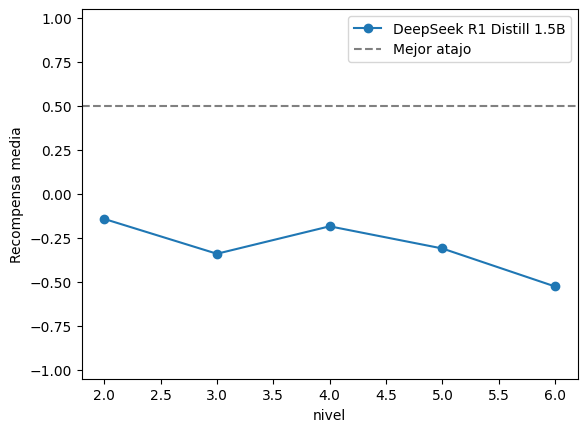

In [11]:
ax = resumen['recompensa'].unstack('modelo').plot(
    marker='o',
    ylim=(-1.05, 1.05),
    ylabel='Recompensa media'
)

ax.axhline(0.5, color='gray', linestyle='--', label='Mejor atajo')
ax.legend();